# Network flows

This notebook shows what the network flows part of the traffic generator does with a week of junction counts: how it spreads them over the roads and turns of the single intersection and of the 2x2 grid, how far it has to move away from the preferred turn shares to meet the counts, and how the result reacts to the config. The model is described in `docs/network-flows.md`.

The raw data has no road or turn information, so nothing here is compared with real flows. The checks are about consistency with the config and with the junction totals. The fit of the junction counts themselves is in `junction_counts_fit.ipynb`.

Run `uv run python scripts/download_kaggle_data.py` first to get the data. The logic lives in the `trafficgen` package. The notebook only calls it.

In [1]:
from dataclasses import replace
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from trafficgen import (
    FlowSolver,
    fit_count_models,
    load_counts_config,
    load_network_config,
    sample_junctions,
)

SINGLE_PATH = Path("../configs/single_intersection.toml")
GRID_PATH = Path("../configs/grid_2x2.toml")
START, END = "2017-04-03", "2017-04-10"
SEED = 0

COLORS = {"J1": "#2a78d6", "J2": "#eb6834", "J3": "#1baf7a", "J4": "#8a5cc7"}

plt.rcParams.update(
    {
        "figure.dpi": 90,
        "figure.facecolor": "#fcfcfb",
        "axes.facecolor": "#fcfcfb",
        "axes.edgecolor": "#c3c2b7",
        "axes.labelcolor": "#52514e",
        "axes.titlecolor": "#0b0b0b",
        "axes.grid": True,
        "axes.axisbelow": True,
        "axes.spines.top": False,
        "axes.spines.right": False,
        "grid.color": "#e1e0d9",
        "grid.linewidth": 0.8,
        "xtick.color": "#52514e",
        "ytick.color": "#52514e",
        "lines.linewidth": 1.8,
        "legend.frameon": False,
    }
)

## 1. Input: junction counts

The network flows take requested vehicles per hour for every junction. Here they come from the junction counts part, sampled for one week with all four junctions together. Any other source in the same format would work the same way.

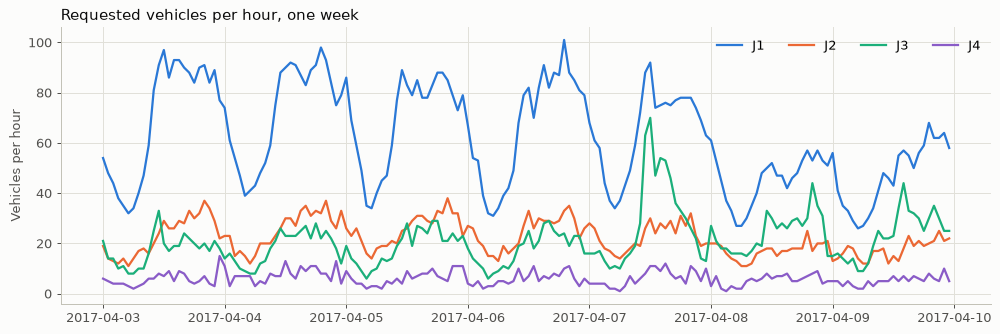

,J1,J2,J3,J4
mean,62.2,22.2,21.1,6.0
min,26.0,11.0,6.0,1.0
max,101.0,38.0,70.0,15.0


In [2]:
count_models = fit_count_models(load_counts_config(GRID_PATH))
counts = sample_junctions(count_models, START, END, seed=SEED)

figure, axis = plt.subplots(figsize=(11, 3.6), layout="constrained")
for junction in counts:
    axis.plot(counts.index, counts[junction], color=COLORS[junction], label=junction)
axis.set_title("Requested vehicles per hour, one week", loc="left")
axis.set_ylabel("Vehicles per hour")
axis.legend(loc="upper right", ncols=4)
plt.show()
counts.describe().loc[["mean", "min", "max"]].round(1)

## 2. Single intersection

With one junction there are no roads between junctions, so nothing has to be balanced. The count of J1 enters on the four approaches in proportion to their preferences (equal here), and every approach splits into right, straight and left turns in the preferred shares 15/70/15.

In [3]:
single = load_network_config(SINGLE_PATH)
single_flows = FlowSolver(single).solve(counts[["J1"]])

first_hour = single_flows.turn_flows[single_flows.turn_flows["datetime"] == counts.index[8]]
print("hours with adjusted shares:", len(single_flows.adjusted_hours))
print("largest |achieved - requested|:", single_flows.junction_balance["difference"].abs().max())
first_hour.round({"vehicles_per_hour": 2})

hours with adjusted shares: 0
largest |achieved - requested|: 0.0


,datetime,junction,from_road,to_road,preferred_share,share,vehicles_per_hour
96,2017-04-03 08:00:00,J1,-E0,E2,0.15,0.15,1.76
97,2017-04-03 08:00:00,J1,-E0,E3,0.70,0.70,8.22
98,2017-04-03 08:00:00,J1,-E0,E1,0.15,0.15,1.76
99,2017-04-03 08:00:00,J1,-E1,E0,0.15,0.15,1.76
100,2017-04-03 08:00:00,J1,-E1,E2,0.70,0.70,8.22
101,2017-04-03 08:00:00,J1,-E1,E3,0.15,0.15,1.76
102,2017-04-03 08:00:00,J1,-E2,E3,0.15,0.15,1.76
103,2017-04-03 08:00:00,J1,-E2,E1,0.70,0.70,8.22
104,2017-04-03 08:00:00,J1,-E2,E0,0.15,0.15,1.76
105,2017-04-03 08:00:00,J1,-E3,E1,0.15,0.15,1.76


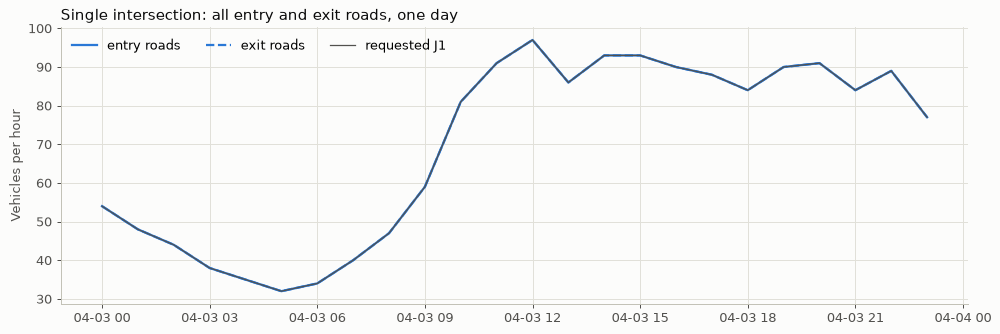

In [4]:
day = single_flows.road_flows[single_flows.road_flows["datetime"] < "2017-04-04"]
figure, axis = plt.subplots(figsize=(11, 3.6), layout="constrained")
for kind, style in (("entry", "-"), ("exit", "--")):
    rows = day[day["kind"] == kind]
    total = rows.groupby("datetime")["vehicles_per_hour"].sum()
    axis.plot(
        total.index, total.to_numpy(), linestyle=style, color="#2a78d6", label=f"{kind} roads"
    )
axis.plot(
    counts.index[:24], counts["J1"].iloc[:24], color="#52514e", linewidth=1, label="requested J1"
)
axis.set_title("Single intersection: all entry and exit roads, one day", loc="left")
axis.set_ylabel("Vehicles per hour")
axis.legend(loc="upper left", ncols=3)
plt.show()

Everything that enters also leaves, and both equal the requested count of J1.

## 3. 2x2 grid

In the grid, a vehicle is counted at every junction it passes, so the counts cannot simply be placed on the outer roads (section 4 shows what that would do). For every hour, the solver works in two steps:

1. Vehicles enter at the boundary and follow the preferred shares. The entry flow of every junction is fitted with non-negative least squares, so that the traffic through each junction is as close to its count as possible.
2. If a junction total is still missed, the flows closest to those of step 1 that meet every total exactly are used. The totals are fixed, the shares give way.

The junctions are numbered J1 (A0, bottom left), J2 (B0, bottom right), J3 (A1, top left) and J4 (B1, top right). J1 is about three times busier than its neighbours.

In [5]:
grid = load_network_config(GRID_PATH)
flows = FlowSolver(grid).solve(counts)

print("hours:", len(counts))
print("hours with adjusted shares:", len(flows.adjusted_hours))
print("hours with an unmet total:", len(flows.unbalanced_hours))
balance = flows.junction_balance.groupby("junction")
pd.DataFrame(
    {
        "mean requested": balance["requested"].mean(),
        "mean achieved": balance["achieved"].mean(),
        "largest |difference|": balance["difference"].apply(lambda d: d.abs().max()),
    }
).round(3)

hours: 168
hours with adjusted shares: 168
hours with an unmet total: 0


,mean requested,mean achieved,largest |difference|
junction,,,
J1,62.226,62.226,0.0
J2,22.208,22.208,0.0
J3,21.125,21.125,0.0
J4,6.036,6.036,0.0


Every total is met. With these counts, the preferred shares alone cannot meet them in any hour: from busy J1, 70% of the traffic heads straight on to a quieter neighbour, which would then get more vehicles than its own count. So the shares are adjusted in every hour.

### Preferred and used turn shares

Each point is one turn. The used share is averaged over the week, and the vertical line spans the 10th to 90th percentile of the hourly values. Points on the diagonal use their preferred share.

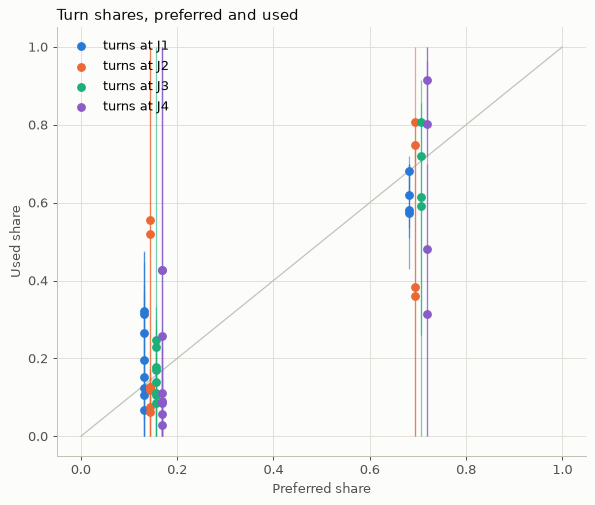

mean |used - preferred| over all turns and hours: 0.142


In [6]:
turn_shares = flows.turn_flows.groupby(["junction", "from_road", "to_road", "preferred_share"])[
    "share"
]
summary = pd.DataFrame(
    {
        "mean": turn_shares.mean(),
        "p10": turn_shares.quantile(0.1),
        "p90": turn_shares.quantile(0.9),
    }
).reset_index()

figure, axis = plt.subplots(figsize=(6.5, 5.5), layout="constrained")
axis.plot([0, 1], [0, 1], color="#c3c2b7", linewidth=1)
for junction, rows in summary.groupby("junction"):
    jitter = (list(COLORS).index(junction) - 1.5) * 0.012
    x = rows["preferred_share"] + jitter
    axis.vlines(x, rows["p10"], rows["p90"], color=COLORS[junction], linewidth=1, alpha=0.6)
    axis.scatter(
        x, rows["mean"], color=COLORS[junction], s=36, label=f"turns at {junction}", zorder=3
    )
axis.set_xlabel("Preferred share")
axis.set_ylabel("Used share")
axis.set_title("Turn shares, preferred and used", loc="left")
axis.legend(loc="upper left")
plt.show()

deviation = (flows.turn_flows["share"] - flows.turn_flows["preferred_share"]).abs()
print("mean |used - preferred| over all turns and hours:", round(deviation.mean(), 3))

In [7]:
summary.assign(change=summary["mean"] - summary["preferred_share"]).sort_values(
    "change", key=abs, ascending=False
).head(8).round(3)

,junction,from_road,to_road,preferred_share,mean,p10,p90,change
15,J2,B1B0,B0A0,0.15,0.555,0.148,1.000,0.405
42,J4,right1B1,B1A1,0.70,0.314,0.000,0.700,-0.386
18,J2,bottom1B0,B0A0,0.15,0.520,0.150,1.000,0.370
19,J2,bottom1B0,B0B1,0.70,0.359,0.000,0.700,-0.341
16,J2,B1B0,B0bottom1,0.70,0.382,0.000,0.749,-0.318
47,J4,top1B1,B1right1,0.15,0.428,0.000,1.000,0.278
44,J4,right1B1,B1top1,0.15,0.428,0.000,1.000,0.278
46,J4,top1B1,B1B0,0.70,0.482,0.000,1.000,-0.218


The largest changes are at the quiet junctions J2 and J4. Turns onto roads that lead to another junction lose share, and turns towards the boundary or back towards J1 gain it, so that vehicles leave the network sooner instead of being counted again at the next junction.

### Where the traffic enters

The traffic through a junction is what enters there from outside plus what arrives from its neighbours.

In [8]:
entering = flows.entry_flows.groupby("junction")["vehicles_per_hour"].sum() / len(counts)
requested = counts.mean()
pd.DataFrame(
    {
        "mean requested": requested,
        "mean entering from outside": entering,
        "share from neighbours": 1 - entering / requested,
    }
).round(2)

,mean requested,mean entering from outside,share from neighbours
J1,62.23,60.45,0.03
J2,22.21,0.51,0.98
J3,21.12,2.34,0.89
J4,6.04,0.69,0.89


Most of the traffic enters at J1, the busiest junction, and the quieter junctions receive nearly all of their traffic from it. With other counts, for example equal ones, every junction gets its own entry flow. This is a consequence of the counts and of the network, not of the solver: a large junction next to small ones has to send its traffic somewhere.

### Flows between the junctions over one day

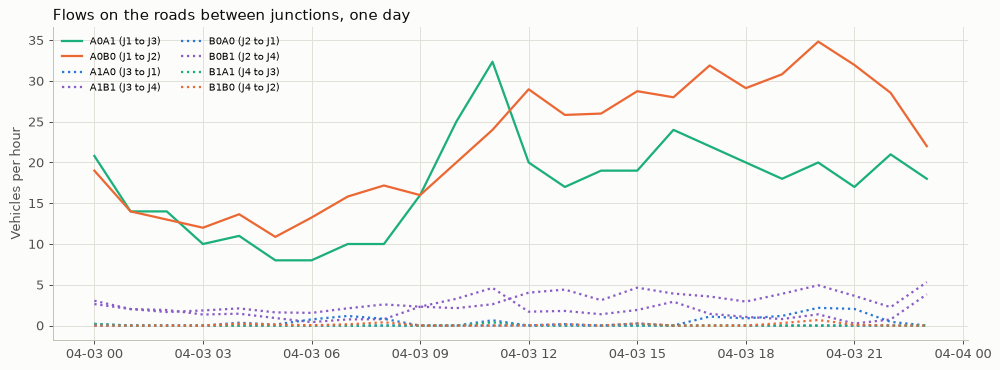

In [9]:
day = flows.road_flows[
    (flows.road_flows["kind"] == "internal") & (flows.road_flows["datetime"] < "2017-04-04")
]
figure, axis = plt.subplots(figsize=(11, 4), layout="constrained")
for road, rows in day.groupby("road"):
    source = rows["from_junction"].iloc[0]
    target = rows["to_junction"].iloc[0]
    style = "-" if source == "J1" else ":"
    axis.plot(
        rows["datetime"],
        rows["vehicles_per_hour"],
        linestyle=style,
        color=COLORS[target],
        label=f"{road} ({source} to {target})",
    )
axis.set_title("Flows on the roads between junctions, one day", loc="left")
axis.set_ylabel("Vehicles per hour")
axis.legend(loc="upper left", ncols=2, fontsize=8)
plt.show()

## 4. Placing counts directly on the outer roads

The simplest approach would insert the count of each junction on its own entry roads and let the vehicles follow the preferred shares. Every vehicle is then counted again at the next junctions, so the traffic through the junctions is far above the counts.

In [10]:
roads = grid.roads
entry_shares = grid.preferred_entry_shares()
entry_matrix = np.array(
    [
        [entry_shares[r] if road.to_junction == j else 0.0 for j in grid.junction_ids]
        for r, road in enumerate(roads)
    ]
)
end_matrix = np.array([[float(road.to_junction == j) for road in roads] for j in grid.junction_ids])
road_flow_per_vehicle = np.linalg.solve(
    np.eye(len(roads)) - grid.preferred_transfer_matrix(), entry_matrix
)
junctions_passed = end_matrix @ road_flow_per_vehicle

direct = counts.to_numpy() @ junctions_passed.T
print("junctions passed per entering vehicle, on average:", junctions_passed.sum(axis=0).round(2))
achieved = flows.junction_balance.groupby("junction")["achieved"].mean()
pd.DataFrame(
    {
        "mean requested": counts.mean(),
        "mean through, placed directly": direct.mean(axis=0),
        "ratio": direct.mean(axis=0) / counts.mean().to_numpy(),
        "mean through, network flows": achieved,
    }
).round(2)

junctions passed per entering vehicle, on average: [2. 2. 2. 2.]


,mean requested,"mean through, placed directly",ratio,"mean through, network flows"
J1,62.23,82.02,1.32,62.23
J2,22.21,54.65,2.46,22.21
J3,21.12,53.70,2.54,21.13
J4,6.04,32.83,5.44,6.04


## 5. How the result reacts to the config

Each variant changes one assumption of the grid and solves the same week again:

- **straight**: the preferred share of going straight, with right and left sharing the rest equally.
- **through share**: the share of vehicles that reach the end of a road between two junctions. A lower value means more vehicles leave on the way, for example to park.

Entry road preferences only move traffic between the outer roads of the same junction, so they are not varied.

In [11]:
def variant(straight=0.7, through_share=1.0):
    """The grid with other preferred turn shares and through shares."""
    turns = tuple(
        replace(turn, preference=straight if turn.preference == 0.7 else (1 - straight) / 2)
        for turn in grid.turns
    )
    roads = tuple(
        replace(road, through_share=through_share) if road.kind == "internal" else road
        for road in grid.roads
    )
    return replace(grid, turns=turns, roads=roads)


rows = {}
for straight, through_share in [(0.5, 1.0), (0.7, 1.0), (0.9, 1.0), (0.7, 0.8), (0.7, 0.6)]:
    result = FlowSolver(variant(straight, through_share)).solve(counts)
    turns, entries = result.turn_flows, result.entry_flows
    entering = entries.groupby("junction")["vehicles_per_hour"].sum()
    rows[(straight, through_share)] = {
        "hours with adjusted shares": len(result.adjusted_hours),
        "mean |used - preferred|": (turns["share"] - turns["preferred_share"]).abs().mean(),
        "share entering at J1": entering["J1"] / entering.sum(),
        "unmet hours": len(result.unbalanced_hours),
    }
pd.DataFrame(rows).T.rename_axis(["straight", "through share"]).round(3)

hours with adjusted shares  mean |used - preferred|  \
straight through share                                                        
0.5      1.0                                 168.0                    0.145   
0.7      1.0                                 168.0                    0.142   
0.9      1.0                                 168.0                    0.145   
0.7      0.8                                 160.0                    0.113   
         0.6                                 110.0                    0.059   

                        share entering at J1  unmet hours  
straight through share                                     
0.5      1.0                           0.939          0.0  
0.7      1.0                           0.945          0.0  
0.9      1.0                           0.911          0.0  
0.7      0.8                           0.901          0.0  
         0.6                           0.811          0.0

The straight share hardly matters: whichever way the vehicles from J1 turn, most of them reach a quieter neighbour. A lower through share removes vehicles between the junctions, so fewer hours need adjusting and the changes get smaller. In every variant the totals are met, and in most hours the preferences are not.

## 6. What remains an assumption

- **Turn and entry preferences.** The data has no directions. 15/70/15 right/straight/left and equal entry roads are a guess, and the used shares can be far from them when neighbouring counts differ a lot.
- **Which junction is where.** The four Kaggle junctions were not neighbours of each other in reality, as far as the data shows. Placing J1 next to quieter junctions is what forces most of the adjustments.
- **Counts as traffic through a junction.** Each count is taken as the vehicles entering the junction in that hour, counted again at every junction they pass.
- **Hourly rates.** Flows are rates within an hour. Travel times between junctions (about 20 s here) are far below an hour and are ignored.
- **through_share.** Vehicles leaving a road on the way are a parameter, not measured.
- **Vehicle types.** All vehicles are the same. Types can be added when the flows are turned into SUMO input.